# Notebook 04: mesoscopic spatial snapshots

This notebook reads `SpeciesMesoSpatial.h5` through `Dump.meso` (a `SpeciesMesoSpatialFile`): per-event snapshots of the mesoscopic stage, i.e. the occupied cells of Geant4's chemistry cell mesh (position, molecule count per species) at each record time. The file layout is described in `docs/output/SpeciesMesoSpatial-h5.md`.

The input is the tiny seeded run of `notebooks/demo_meso_spatial.in` (10 keV electrons, **two events**, end time 1 ms). It is a **workflow demonstration**, not a converged result. Run the cells from top to bottom in a fresh kernel; edit `MESO_DUMP`, `RUN`, `EVENT` and `SNAPSHOT_TIME_NS` in the next cell to inspect other output.

**Cell size, requested vs actual.** The macro requests the default 6.25 nm cells, but the mesh is capped at 65,536 pixels per side (`G4DNAMesh::ConvertIndex` overflows `int` above that; ADR 0006), so on the default 1 mm box the **actual** cell is 15.26 nm, not 6.25 nm. The plots below use the `cellSize_nm` stored in the file, never the requested value. The file also shows the cell growing at later record times (the mesh coarsens as the chemistry proceeds).

**Output.** Only one selected snapshot is exported to CSV, to a directory outside Git (default under the ignored `.scratch/`); the HDF5 file itself is never copied.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

from g4utils.DnaChem import Dump

dev_dir = os.environ.get('DEV_DIR')
if not dev_dir:
    raise RuntimeError(
        'DEV_DIR is unset. Run ~/dotfiles/scripts/windows/setup-dev-env.ps1 and restart the shell before using this notebook.'
    )
DEV_DIR = Path(dev_dir)
REPO = DEV_DIR / 'GEANT4' / 'SIM' / 'dnachem-min'

DEFAULT_RUN_ROOT = (
    REPO / '.scratch' / 'tests'
    / '2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the'
)

# Edit these for different data (unprefixed dump with its own Manifest.json).
MESO_DUMP = DEFAULT_RUN_ROOT / 'meso-spatial'
RUN = 0                    # run number in the HDF5 file
EVENT = 0                  # event number within the run
SNAPSHOT_TIME_NS = 5.0     # the snapshot nearest to this record time is selected
# CSV export directory: keep it outside Git (this default is under the ignored .scratch/).
EXPORT_DIR = REPO / '.scratch' / 'notebook-exports' / '04_meso_spatial'

README_HINT = (
    'The spatial file is missing. Regenerate it with notebooks/demo_meso_spatial.in '
    '(sim.exe demo_meso_spatial.in --dir <dir>); see notebooks/README.md ("Reproduce the runs").'
)

mf = MESO_DUMP / 'Manifest.json'
meso = None
if not mf.is_file() or mf.stat().st_size == 0:
    print(f'No usable Manifest.json at {mf}.\n{README_HINT}\nThe remaining cells are skipped.')
else:
    dump = Dump.from_manifest(mf)
    try:
        meso = dump.meso
    except FileNotFoundError as exc:
        print(f'{exc}\n{README_HINT}\nThe remaining cells are skipped.')
    else:
        m = dump.manifest
        print(f'Dump: {dump.path.resolve()}')
        print(f'  model={m.chemistryModel}, events={m.totalEvents}, hand-over={m.handOverTime_ns} ns, '
              f'requested voxel={m.voxelSize_nm} nm, mesoPixels={m.mesoPixels}')
        print(f'  {meso}  (format version {meso.format_version})')
        print(f'  units: {meso.units}')

Dump: C:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\meso-spatial
  model=IRT_syn+mesoscopic, events=2, hand-over=5 ns, requested voxel=6.25 nm, mesoPixels=65536
  SpeciesMesoSpatialFile('C:\\DEV\\GEANT4\\SIM\\dnachem-min\\.scratch\\tests\\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\\meso-spatial\\SpeciesMesoSpatial.h5', runs=1, species=16)  (format version 2)
  units: position_nm: nm (cell centre, world frame); cellSize_nm: nm (cell side); time_ns: ns; counts: molecules per cell


## 1. Inventory: snapshots, record times and cell sizes

The index is read once when the file is opened; array data are read on demand. Each event has one snapshot per record time. The table lists, for the selected run and event, the record time, the actual cell size stored in the file, and the number of occupied cells and molecules (read one snapshot at a time).

runs=[0]; events in run 0: [0, 1]; 16 species columns
species: ['H2O2^0', 'H3O^1', 'HO_2^-1', 'HO_2°^0', 'H^0', 'H_2^0', 'OH^-1', 'O^-1', 'O^0', 'O_2^-1', 'O_2^0', 'O_3^-1', 'O_3^0', 'e_aq^-1', '°OH^0', '°O^0']
run 0, event 0: 55 snapshots


,index,time_ns,cell_size_nm,occupied_cells,molecules
0,0,5.000000,15.258789,550,1158
5,5,15.811388,15.258789,721,1078
10,10,50.000000,15.258789,870,1022
15,15,158.113883,15.258789,939,978
20,20,500.000000,15.258789,896,915
25,25,1581.138830,30.517578,849,874
30,30,5000.000000,61.035156,785,840
35,35,15811.388301,122.070312,668,776
40,40,50000.000000,244.140625,530,678
45,45,158113.883008,488.281250,404,554


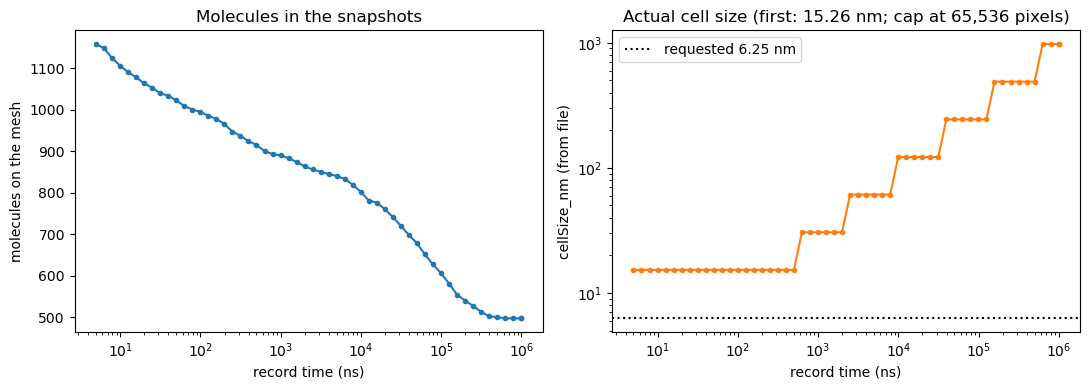

In [2]:
if meso is None:
    print('Skipped: no spatial file (see the configuration cell).')
else:
    print(f'runs={meso.runs}; events in run {RUN}: {meso.events(RUN)}; {len(meso.species)} species columns')
    print('species:', meso.species)
    rows = []
    for k in meso.snapshot_indices(RUN, EVENT):
        s = meso.read_snapshot(RUN, EVENT, k)
        rows.append(dict(index=k, time_ns=s.time_ns, cell_size_nm=s.cell_size_nm,
                         occupied_cells=len(s.position_nm), molecules=int(s.counts.sum())))
    inv = pd.DataFrame(rows)
    print(f'run {RUN}, event {EVENT}: {len(inv)} snapshots')
    display(inv.iloc[::5])

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(inv.time_ns, inv.molecules, 'o-', ms=3)
    ax[0].set_xscale('log'); ax[0].set_xlabel('record time (ns)'); ax[0].set_ylabel('molecules on the mesh')
    ax[0].set_title('Molecules in the snapshots')
    ax[1].plot(inv.time_ns, inv.cell_size_nm, 'o-', ms=3, color='C1')
    ax[1].axhline(m.voxelSize_nm, color='k', ls=':', label=f'requested {m.voxelSize_nm} nm')
    ax[1].set_xscale('log'); ax[1].set_yscale('log')
    ax[1].set_xlabel('record time (ns)'); ax[1].set_ylabel('cellSize_nm (from file)')
    ax[1].set_title(f'Actual cell size (first: {inv.cell_size_nm.iloc[0]:.2f} nm; cap at 65,536 pixels)')
    ax[1].legend()
    plt.tight_layout(); plt.show()

## 2. One selected snapshot

The snapshot nearest to `SNAPSHOT_TIME_NS` is read with `read_snapshot(run, event, index)`. `position_nm` holds cell centres (x, y, z) in the world frame and `counts` the molecules per cell and species; only occupied cells are stored. The plot projects the occupied cells onto the x-y plane, each drawn as a square of side `cellSize_nm` from the file, coloured by the total molecule count of the cell. Cells at different z overlap in the projection, so read it as a qualitative view.

Selected run 0, event 0, snapshot 0: t = 5 ns, cellSize_nm = 15.2588 (requested 6.25 nm), 550 occupied cells, 1158 molecules


,molecules
H3O^1,329
°OH^0,302
e_aq^-1,283
H^0,84
H_2^0,47
H2O2^0,45
OH^-1,38
°O^0,9
HO_2°^0,8
O^-1,7


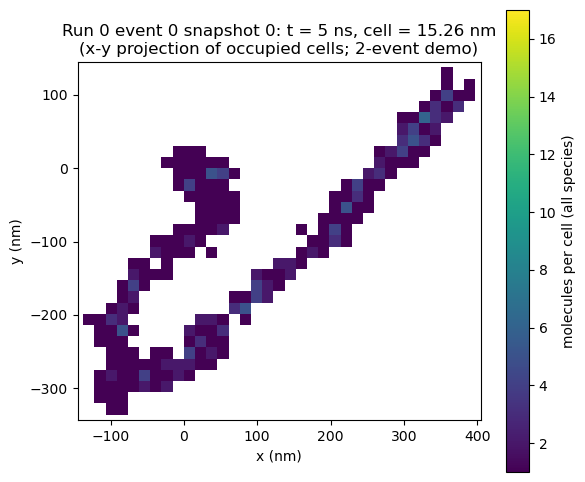

In [3]:
if meso is None:
    print('Skipped: no spatial file (see the configuration cell).')
else:
    idx = int(inv.index[(inv.time_ns - SNAPSHOT_TIME_NS).abs().argmin()])
    idx = int(inv['index'].iloc[idx])
    snap = meso.read_snapshot(RUN, EVENT, idx)
    cell = snap.cell_size_nm
    total = snap.counts.sum(axis=1)
    print(f'Selected run {RUN}, event {EVENT}, snapshot {idx}: t = {snap.time_ns:g} ns, '
          f'cellSize_nm = {cell:.4f} (requested {m.voxelSize_nm} nm), '
          f'{len(snap.position_nm)} occupied cells, {int(total.sum())} molecules')
    per_species = pd.Series(snap.counts.sum(axis=0), index=snap.species)
    display(per_species[per_species > 0].sort_values(ascending=False).rename('molecules').to_frame())

    if len(snap.position_nm) == 0:
        print('The snapshot has no occupied cell; nothing to plot.')
    else:
        xy = snap.position_nm[:, :2]
        rects = [Rectangle((x - cell / 2, y - cell / 2), cell, cell) for x, y in xy]
        pc = PatchCollection(rects, cmap='viridis', edgecolor='none')
        pc.set_array(total.astype(float))
        fig, ax = plt.subplots(figsize=(6.5, 6))
        ax.add_collection(pc)
        lo = xy.min(axis=0) - cell; hi = xy.max(axis=0) + cell
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_aspect('equal')
        fig.colorbar(pc, ax=ax, label='molecules per cell (all species)')
        ax.set_xlabel('x (nm)'); ax.set_ylabel('y (nm)')
        ax.set_title(f'Run {RUN} event {EVENT} snapshot {idx}: t = {snap.time_ns:g} ns, cell = {cell:.2f} nm\n(x-y projection of occupied cells; 2-event demo)')
        plt.show()

## 3. Export the selected snapshot to CSV

Only the snapshot selected above is written: one row per occupied cell, with the cell centre, the cell size from the file, and one count column per species (UTF-8). The directory is `EXPORT_DIR`, outside Git by default (`.scratch/` is ignored); change it in the configuration cell. Do not point it inside a tracked folder.

In [4]:
if meso is None:
    print('Skipped: no spatial file (see the configuration cell).')
else:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    out = EXPORT_DIR / f'meso_run{RUN}_event{EVENT}_snapshot{idx}.csv'
    df = pd.DataFrame(snap.position_nm, columns=['x_nm', 'y_nm', 'z_nm'])
    df.insert(3, 'cellSize_nm', cell)
    df.insert(0, 'time_ns', snap.time_ns)
    for j, sp in enumerate(snap.species):
        df[sp] = snap.counts[:, j]
    df.to_csv(out, index=False, encoding='utf-8')
    print(f'Wrote {out} ({out.stat().st_size / 1024:.1f} KiB, {len(df)} rows, {df.shape[1]} columns)')
    check = pd.read_csv(out)
    assert len(check) == len(snap.position_nm)
    assert int(check[snap.species].to_numpy().sum()) == int(snap.counts.sum())
    print('Round-trip check passed: row count and total molecules match the snapshot.')
    display(check.head())

Wrote C:\DEV\GEANT4\SIM\dnachem-min\.scratch\notebook-exports\04_meso_spatial\meso_run0_event0_snapshot0.csv (60.8 KiB, 550 rows, 21 columns)
Round-trip check passed: row count and total molecules match the snapshot.


,time_ns,x_nm,y_nm,z_nm,cellSize_nm,H2O2^0,H3O^1,HO_2^-1,HO_2°^0,H^0,...,OH^-1,O^-1,O^0,O_2^-1,O_2^0,O_3^-1,O_3^0,e_aq^-1,°OH^0,°O^0
0,5.0,-129.699707,-205.993652,1426.696777,15.258789,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,5.0,-114.440918,-312.805176,1731.872559,15.258789,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,5.0,-114.440918,-297.546387,1731.872559,15.258789,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,5.0,-114.440918,-297.546387,1747.131348,15.258789,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,5.0,-114.440918,-297.546387,1823.425293,15.258789,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
